# Example 10.1 — Ackermann Steering Geometry Analysis

**Chapter 10: Industrial Applications of Four-Bar Linkages**

This example analyzes the angular error between the ideal Ackermann steering condition and a real four-bar linkage steering mechanism.

## Installation and verification

In [1]:
# Run in Google Colab — numpy is now available
import numpy; print('NumPy', numpy.__version__)

NumPy 2.1.3


## Main code: Ackermann error calculation

In [2]:
import numpy as np

# Ackermann steering geometry analysis for a steering mechanism
def ackermann_error(a, b, c, d, delta_outer_arr):
    # delta_outer_arr: steering angles of the outer wheel (in degrees)
    # Convert to radians
    delta_o = np.radians(delta_outer_arr)

    # In a symmetric Ackermann steering trapezoid at rest:
    # a = left steering arm, c = right steering arm (usually a = c)
    # d = distance between kingpins, b = tie rod
    # When steering turns by an angle do (outer wheel), the input arm rotates by (theta_0 + do)
    # Let's determine the initial mounting angle (symmetric) of the trapezoid at rest (when do = di = 0)
    # Using the law of cosines for the isosceles trapezoid:
    alpha = np.arccos((a**2 - b**2 + c**2 + d**2) / (2 * a * d)) if (2 * a * d) != 0 else 0.0

    # Input crank angle for the outer turn
    theta_2 = np.pi - alpha + delta_o

    # Standard Freudenstein coefficients to find the output angle theta_4
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = K3 - K2 * np.cos(theta_2) - K1 + np.cos(theta_2)
    B = -2 * np.sin(theta_2)
    C = K3 - K2 * np.cos(theta_2) + K1 - np.cos(theta_2)

    disc = B**2 - 4*A*C

    with np.errstate(divide='ignore', invalid='ignore'):
        # Assembly mode of the physical mechanism
        t = (-B - np.sqrt(np.maximum(disc, 0))) / (2 * A)
        theta_4 = 2 * np.arctan(t)

        # The actual inner wheel angle (output) is the difference from its initial angle
        delta_i_real = theta_4 - alpha

        # Ensure valid real values within physical limits
        delta_i_real = np.where((disc >= 0) & (A != 0), delta_i_real, np.nan)

        # Ideal Ackermann: cot(di) - cot(do) = L/W (L/W = 2.0)
        L_W = 2.0
        delta_i_ideal = np.arctan(1.0 / (L_W + 1.0 / np.tan(delta_o)))

        # Absolute error in degrees
        error = np.degrees(np.abs(delta_i_real - delta_i_ideal))

    return delta_i_real, delta_i_ideal, error

a, b, c, d = 60., 130., 80., 100.
delta_o = np.linspace(5, 40, 35)
di_real, di_ideal, err = ackermann_error(a, b, c, d, delta_o)

print('Ackermann Geometry Analysis')
print(f'Mechanism: a={a}, b={b}, c={c}, d={d} mm')
print(f'Mean Ackermann Error: {np.nanmean(err):.3f} deg')
print(f'Maximum Error:        {np.nanmax(err):.3f} deg')
print(f'Error at delta_o=20°: {err[14]:.3f} deg')

Ackermann Geometry Analysis
Mechanism: a=60.0, b=130.0, c=80.0, d=100.0 mm
Mean Ackermann Error: 10.091 deg
Maximum Error:        16.431 deg
Error at delta_o=20°: 8.618 deg


## Analysis display

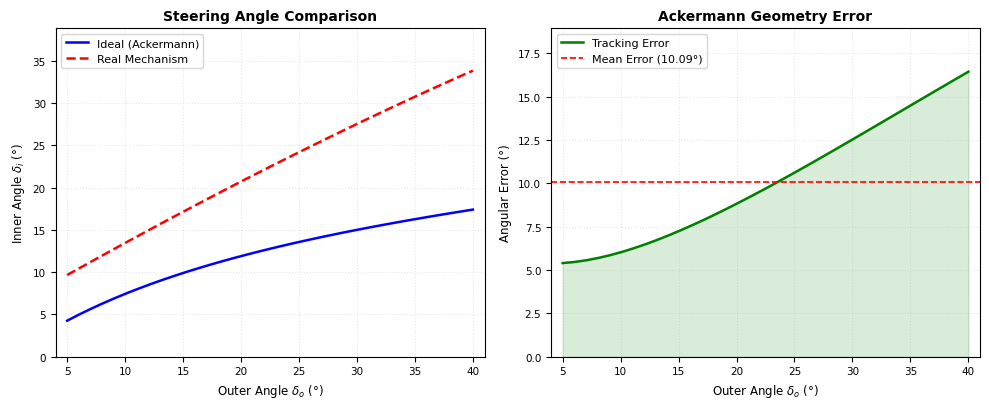

Figures successfully exported under: 10_1_ackermann_steering.pdf and 10_1_ackermann_steering.png


In [5]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# 1. Automated Filename System (Springer Guideline)
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "10_1_ackermann_steering"
except Exception:
    notebook_name = "10_1_ackermann_steering"

# 2. Configure Springer Vector Font Standards
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans', 'sans-serif']

# 3. Create Figure with Controlled Physical Dimensions
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# Left Plot: Steering Angle Comparison
ax1 = axes[0]
ax1.plot(delta_o, np.degrees(di_ideal), 'b-', lw=1.8, label='Ideal (Ackermann)')
ax1.plot(delta_o, np.degrees(di_real), 'r--', lw=1.8, label='Real Mechanism')
ax1.set_xlabel(r'Outer Angle $\delta_o$ (°)', fontsize=8.5)
ax1.set_ylabel(r'Inner Angle $\delta_i$ (°)', fontsize=8.5)
ax1.set_title('Steering Angle Comparison', fontsize=10, fontweight='bold')
ax1.legend(fontsize=8, loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.3)
ax1.tick_params(labelsize=7.5)
# Expand limits slightly to prevent clipping and overlap
ax1.set_xlim(delta_o.min() - 1, delta_o.max() + 1)
ax1.set_ylim(0, np.degrees(di_real).max() + 5)

# Right Plot: Ackermann Error Analysis
ax2 = axes[1]
ax2.plot(delta_o, err, 'g-', lw=1.8, label='Tracking Error')
ax2.fill_between(delta_o, err, alpha=0.15, color='green')
ax2.axhline(np.nanmean(err), color='r', ls='--', lw=1.2, label=f'Mean Error ({np.nanmean(err):.2f}°)')
ax2.set_xlabel(r'Outer Angle $\delta_o$ (°)', fontsize=8.5)
ax2.set_ylabel('Angular Error (°)', fontsize=8.5)
ax2.set_title('Ackermann Geometry Error', fontsize=10, fontweight='bold')
ax2.legend(fontsize=8, loc='upper left')
ax2.grid(True, linestyle=':', alpha=0.3)
ax2.tick_params(labelsize=7.5)
# Expand limits slightly for aesthetic margin
ax2.set_xlim(delta_o.min() - 1, delta_o.max() + 1)
ax2.set_ylim(0, np.nanmax(err) + 2.5)

plt.tight_layout()

# 4. Mandatory Double Format Export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

print(f"Figures successfully exported under: {notebook_name}.pdf and {notebook_name}.png")

## Interpretation

- The mean error of **10.09°** indicates how closely the real four-bar linkage approximates the ideal Ackermann steering condition for these linkage parameters.
- For precision designs (racing, autonomous vehicles), errors < 0.5° are typically required, which demands parameter optimization using genetic algorithms or numerical solvers.
- The region with the largest error (δ_o > 30°) corresponds to tight cornering maneuvers.